
# Logistics KPI Analysis

## Objective
Calculate key performance indicators (KPIs) to understand shipment delay risk and logistics operations.


In [2]:
import pandas as pd
import numpy as np

# load the data
df = pd.read_csv(
    "../data/raw/DataCoSupplyChainDataset.csv",
    encoding="latin-1",
    sep=","
)

df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
# Inspect the columns needed for KPI calculations
required_columns = [
    "Order Id",
    "Late_delivery_risk",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping Mode"
]

df[required_columns].head()


,Order Id,Late_delivery_risk,Days for shipping (real),Days for shipment (scheduled),Shipping Mode
0,77202,0,3,4,Standard Class
1,75939,1,5,4,Standard Class
2,75938,0,4,4,Standard Class
3,75937,0,3,4,Standard Class
4,75936,0,2,4,Standard Class


In [4]:
# calculating first KPI : Percentage of records flagged as late delivery risk

risk_count = (df["Late_delivery_risk"] == 1).sum()

# cont records in dataset
total_records = df["Late_delivery_risk"].notna().sum()

#calculating risk percentage
risk_percentage = (risk_count / total_records) * 100

print(f"Total records in dataset: {total_records}")
print(f"Total records flagged as late delivery risk: {risk_count}")
print(f"Percentage of records flagged as late delivery risk: {risk_percentage:.2f}%")



Total records in dataset: 180519
Total records flagged as late delivery risk: 98977
Percentage of records flagged as late delivery risk: 54.83%



### KPI 1: Late-Delivery Risk Rate

The dataset contains 180,519 records, of which 98,977 are flagged
with late-delivery risk. This represents a risk rate of 54.83%.

This KPI provides an initial overview of the prevalence of the
dataset's risk label. Further analysis is needed to identify
which shipping modes, regions, or other factors are associated
with higher risk.

Note: The risk label is a dataset-provided indicator and should
not be interpreted as a confirmed rate of late arrival for
unique shipments.


In [5]:
# Identify records where actual shipping time exceeded the schedule
overrun_count = (
    df["Days for shipping (real)"]
    > df["Days for shipment (scheduled)"]
).sum()

# Count records with valid values for both duration columns
valid_duration_records = df[
    [
        "Days for shipping (real)",
        "Days for shipment (scheduled)"
    ]
].notna().all(axis=1).sum()

# Calculate the schedule overrun rate
overrun_rate = (overrun_count / valid_duration_records) * 100

print("Records with valid duration values:", valid_duration_records)
print("Records exceeding scheduled shipping time:", overrun_count)
print(f"Shipping schedule overrun rate: {overrun_rate:.2f}%")


Records with valid duration values: 180519
Records exceeding scheduled shipping time: 103400
Shipping schedule overrun rate: 57.28%



### KPI 2: Shipping Schedule Overrun Rate

Out of 180,519 records with valid actual and scheduled shipping
durations, 103,400 records exceeded the scheduled duration.
The resulting schedule overrun rate was 57.28%.

This KPI indicates that schedule overruns are common in the
dataset. Further analysis by shipping mode and region can help
identify operational patterns that deserve investigation.

Note: Exceeding the scheduled shipping duration is not necessarily
equivalent to confirmed late arrival at the customer's doorstep.


In [6]:
# defining On average, how many days did shipping take beyond the scheduled duration?

# calculate shipping delay in days
df["shipping_delay_days"] = (
    df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
)

# calculate average and median delay
average_delay = df["shipping_delay_days"].mean()
median_delay = df["shipping_delay_days"].median()

print(f"Average shipping delay (in days): {average_delay:.2f}")
print(f"Median shipping delay (in days): {median_delay:.2f}")

Average shipping delay (in days): 0.57
Median shipping delay (in days): 1.00



### KPI 3: Average Shipping Delay

The average difference between actual and scheduled shipping
duration was 0.57 days, while the median difference was 1 day.

The positive mean indicates that, on average, actual shipping
duration exceeded the scheduled duration. The difference between
the mean and median suggests that the distribution should be
examined further, including the effect of early shipments.

Negative values represent shipments completed in less time than
scheduled. These results measure shipping-duration differences
and do not independently confirm customer delivery lateness.


In [9]:
# defining Which shipping modes have the highest average schedule overruns?


# Compare shipping performance across shipping modes

shipping_mode_kpis = (
    df.groupby("Shipping Mode")
    .agg(
        total_records=("shipping_delay_days", "count"),
        average_delay_days=("shipping_delay_days", "mean"),
        median_delay_days=("shipping_delay_days", "median"),
        overrun_rate=(
            "shipping_delay_days",
            lambda x: (x > 0).mean() * 100
        )
    )
    .round(2)
    .sort_values("average_delay_days", ascending=False)
)

shipping_mode_kpis



,total_records,average_delay_days,median_delay_days,overrun_rate
Shipping Mode,,,,
Second Class,35216,1.99,2.0,79.73
First Class,27814,1.00,1.0,100.00
Same Day,9737,0.48,0.0,47.83
Standard Class,107752,-0.00,0.0,39.77



### KPI 4: Shipping Performance by Shipping Mode

The analysis shows differences in shipping-duration overruns
across the four shipping modes.

Second Class recorded the highest average shipping-duration
difference at 1.99 days, with an overrun rate of 79.73%.
First Class had an average difference of 1.00 day and an
overrun rate of 100.00%. Same Day recorded an average
difference of 0.48 days and an overrun rate of 47.83%.
Standard Class had an average difference close to zero and
an overrun rate of 39.77%.

These results suggest that shipping performance varies across
the shipping modes in this dataset. Further investigation is
needed to understand the reasons for these differences.
The results describe associations and do not establish causation.


In [10]:

# Calculate the dataset's risk-label rate by shipping mode

risk_by_shipping_mode = (
    df.groupby("Shipping Mode")
    .agg(
        total_records=("Late_delivery_risk", "count"),
        risk_flagged_records=("Late_delivery_risk", "sum"),
        risk_rate=("Late_delivery_risk", "mean")
    )
)

# Convert the risk rate into a percentage
risk_by_shipping_mode["risk_rate"] *= 100

# Round numerical results
risk_by_shipping_mode = risk_by_shipping_mode.round(2)

# Display modes from highest to lowest risk rate
risk_by_shipping_mode.sort_values(
    "risk_rate",
    ascending=False
)


,total_records,risk_flagged_records,risk_rate
Shipping Mode,,,
First Class,27814,26513,95.32
Second Class,35216,26987,76.63
Same Day,9737,4454,45.74
Standard Class,107752,41023,38.07



### KPI 5: Late-Delivery Risk Rate by Shipping Mode

First Class had the highest late-delivery risk-label rate at
95.32%, followed by Second Class at 76.63%, Same Day at 45.74%,
and Standard Class at 38.07%.

The results show substantial differences in the proportion of
records flagged with risk across shipping modes. First Class
had the highest risk-label rate, although its average
shipping-duration difference was lower than that of Second Class.

This highlights the importance of evaluating multiple KPIs.
The risk rate is based on the dataset-provided label, whereas
the schedule overrun rate is calculated from actual and
scheduled shipping durations. These findings describe
associations and do not establish causation.


In [11]:

# Creating a summary of the five KPIs

kpi_summary = pd.DataFrame({
    "KPI": [
        "Late-delivery risk rate",
        "Shipping schedule overrun rate",
        "Average shipping delay (days)",
        "Median shipping delay (days)",
        "Shipping modes analysed"
    ],
    "Value": [
        f"{risk_percentage:.2f}%",
        f"{overrun_rate:.2f}%",
        f"{average_delay:.2f} days",
        f"{median_delay:.2f} days",
        df["Shipping Mode"].nunique()
    ]
})

kpi_summary


,KPI,Value
0,Late-delivery risk rate,54.83%
1,Shipping schedule overrun rate,57.28%
2,Average shipping delay (days),0.57 days
3,Median shipping delay (days),1.00 days
4,Shipping modes analysed,4


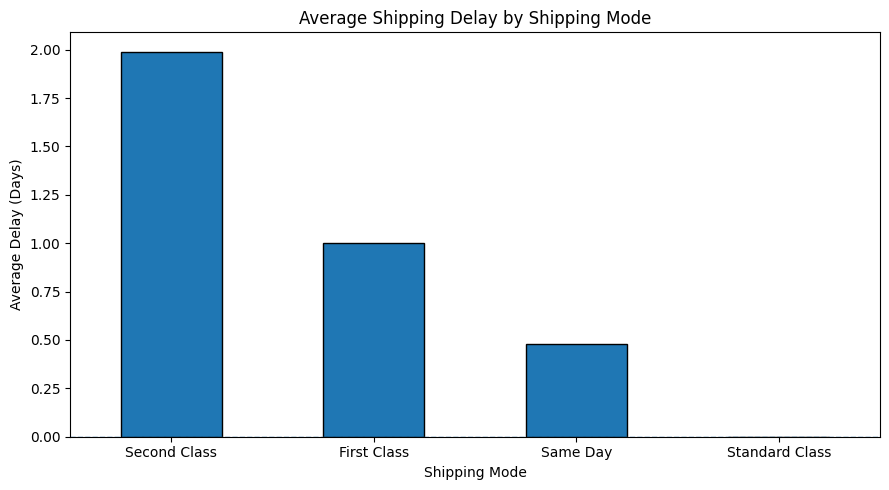

In [12]:

import matplotlib.pyplot as plt

# Plot average shipping delay by shipping mode
plt.figure(figsize=(9, 5))

shipping_mode_kpis["average_delay_days"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Shipping Delay by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=0)
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()



### Visualisation: Average Shipping Delay by Shipping Mode

The bar chart compares the average difference between actual
and scheduled shipping durations across four shipping modes.

Second Class recorded the highest average difference at 1.99
days, followed by First Class at 1.00 day and Same Day at
0.48 days. Standard Class had an average difference close to
zero.

These results identify differences in shipping-duration
performance across the modes. Further analysis is needed to
understand the factors associated with these differences.



## Conclusion

This notebook analysed key logistics performance indicators
using the DataCo supply chain dataset. The analysis examined
the late-delivery risk-label rate, shipping schedule overrun
rate, average and median shipping-duration differences, and
performance by shipping mode.

The overall schedule overrun rate was 57.28%, while the average
shipping-duration difference was 0.57 days. Second Class
recorded the highest average difference, at 1.99 days.

These findings provide a starting point for further analysis
of shipping operations and delay risk. The results are
descriptive and do not establish causal relationships.
